In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Setup

In [ ]:
!pip install -q ucimlrepo pandas numpy tqdm transformers accelerate torch

## 2. Load the Drug Review Dataset (Druglib.com)


In [ ]:
import pandas as pd
import numpy as np
import io, zipfile, urllib.request

def load_druglib():
    """Load and concatenate the Druglib.com train+test TSVs.
    Tries ucimlrepo first, falls back to a direct zip download."""
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=461)
        X = ds.data.features.copy()
        y = ds.data.targets
        if y is not None and len(y.columns) > 0:
            for c in y.columns:
                if c not in X.columns:
                    X[c] = y[c]
        print("Loaded via ucimlrepo. Shape:", X.shape)
        return X
    except Exception as e:
        print("ucimlrepo path failed (", e, "), falling back to direct zip download...")

    url = "https://archive.ics.uci.edu/static/public/461/drug+review+dataset+druglib+com.zip"
    with urllib.request.urlopen(url) as resp:
        buf = io.BytesIO(resp.read())

    with zipfile.ZipFile(buf) as zf:
        names = zf.namelist()
        train_name = [n for n in names if "Train" in n][0]
        print("Found train file:", train_name)
        test_name = [n for n in names if "Test" in n][0]
        with zf.open(train_name) as f:
            train_df = pd.read_csv(f, sep="\t", index_col=0, encoding="latin-1")
        with zf.open(test_name) as f:
            test_df = pd.read_csv(f, sep="\t", index_col=0, encoding="latin-1")

    full_df = pd.concat([train_df, test_df], ignore_index=True)
    print("Loaded via direct zip download. Shape:", full_df.shape)
    return full_df


raw_df = load_druglib()
raw_df.columns = [c.strip() for c in raw_df.columns]
print(raw_df.columns.tolist())
raw_df.head()

Loaded via ucimlrepo. Shape: (4143, 8)
['urlDrugName', 'rating', 'effectiveness', 'sideEffects', 'condition', 'benefitsReview', 'sideEffectsReview', 'commentsReview']


,urlDrugName,rating,effectiveness,sideEffects,condition,benefitsReview,sideEffectsReview,commentsReview
0,enalapril,4,Highly Effective,Mild Side Effects,management of congestive heart failure,slowed the progression of left ventricular dys...,"cough, hypotension , proteinuria, impotence , ...","monitor blood pressure , weight and asses for ..."
1,ortho-tri-cyclen,1,Highly Effective,Severe Side Effects,birth prevention,Although this type of birth control has more c...,"Heavy Cycle, Cramps, Hot Flashes, Fatigue, Lon...","I Hate This Birth Control, I Would Not Suggest..."
2,ponstel,10,Highly Effective,No Side Effects,menstrual cramps,I was used to having cramps so badly that they...,Heavier bleeding and clotting than normal.,I took 2 pills at the onset of my menstrual cr...
3,prilosec,3,Marginally Effective,Mild Side Effects,acid reflux,The acid reflux went away for a few months aft...,"Constipation, dry mouth and some mild dizzines...",I was given Prilosec prescription at a dose of...
4,lyrica,2,Marginally Effective,Severe Side Effects,fibromyalgia,I think that the Lyrica was starting to help w...,I felt extremely drugged and dopey. Could not...,See above


In [ ]:
raw_df.to_csv("01druglib_full.csv", index=False)

## 3. Build the working dataframe


In [ ]:
EFFECTIVENESS_LABELS = [
    "Ineffective",
    "Marginally Effective",
    "Moderately Effective",
    "Considerably Effective",
    "Highly Effective",
]


def build_review_text(row):
    parts = []
    for col in ["benefitsReview", "sideEffectsReview", "commentsReview"]:
        val = row.get(col, "")
        if isinstance(val, str) and val.strip():
            parts.append(val.strip())
    return " ".join(parts)


work_df = raw_df.copy()
work_df["text"] = work_df.apply(build_review_text, axis=1)
work_df["rating"] = pd.to_numeric(work_df["rating"], errors="coerce")
work_df["effectiveness"] = work_df["effectiveness"].astype(str).str.strip()

work_df = work_df.rename(columns={"urlDrugName": "product_id"})
work_df = work_df[["text", "rating", "product_id", "condition", "effectiveness", "sideEffects"]]
work_df = work_df.dropna(subset=["text", "rating", "product_id", "effectiveness"])
work_df = work_df[work_df["text"].str.len() > 0]

# Keep only rows whose effectiveness value matches the known 5-level scale
work_df = work_df[work_df["effectiveness"].isin(EFFECTIVENESS_LABELS)]


def rating_to_label(r):
    if r >= 7:
        return "positive"
    elif r <= 4:
        return "negative"
    else:
        return "neutral"


work_df["label"] = work_df["rating"].apply(rating_to_label)
work_df = work_df[work_df["label"].isin(["positive", "negative"])]

work_df["word_count"] = work_df["text"].astype(str).apply(lambda x: len(x.split()))
work_df = work_df[(work_df["word_count"] >= 20) & (work_df["word_count"] <= 200)]

print(work_df.shape)
print("Binary label counts (used only for sampling):")
print(work_df["label"].value_counts())
print("\nEffectiveness level counts (what fairness is measured against):")
print(work_df["effectiveness"].value_counts())
work_df.head()

(3166, 8)
Binary label counts (used only for sampling):
label
positive    2396
negative     770
Name: count, dtype: int64

Effectiveness level counts (what fairness is measured against):
effectiveness
Highly Effective          1405
Considerably Effective     980
Moderately Effective       324
Ineffective                277
Marginally Effective       180
Name: count, dtype: int64


,text,rating,product_id,condition,effectiveness,sideEffects,label,word_count
0,slowed the progression of left ventricular dys...,4,enalapril,management of congestive heart failure,Highly Effective,Mild Side Effects,negative,63
1,Although this type of birth control has more c...,1,ortho-tri-cyclen,birth prevention,Highly Effective,Severe Side Effects,negative,89
2,I was used to having cramps so badly that they...,10,ponstel,menstrual cramps,Highly Effective,No Side Effects,positive,128
3,The acid reflux went away for a few months aft...,3,prilosec,acid reflux,Marginally Effective,Mild Side Effects,negative,163
4,I think that the Lyrica was starting to help w...,2,lyrica,fibromyalgia,Marginally Effective,Severe Side Effects,negative,50


In [ ]:
work_df.to_csv("work_df_druglib_full_.csv", index=False)

## 4. Build multi-review samples per drug


In [ ]:
from collections import Counter
import random

random.seed(42)
np.random.seed(42)


def create_review_samples(work_df, n_per_condition=30, min_reviews_per_drug=8):
    condition_targets = {
        "balanced": {"positive": 4, "negative": 4},
        "pro_positive": {"positive": 6, "negative": 2},
        "pro_negative": {"positive": 2, "negative": 6},
    }

    samples = []
    condition_counts = Counter()

    grouped = work_df.groupby("product_id")

    for product_id, group in grouped:
        if len(group) < min_reviews_per_drug:
            continue

        pos_reviews = group[group["label"] == "positive"].to_dict("records")
        neg_reviews = group[group["label"] == "negative"].to_dict("records")

        for condition, target in condition_targets.items():
            if condition_counts[condition] >= n_per_condition:
                continue

            if len(pos_reviews) >= target["positive"] and len(neg_reviews) >= target["negative"]:
                selected = (
                    random.sample(pos_reviews, target["positive"]) +
                    random.sample(neg_reviews, target["negative"])
                )
                random.shuffle(selected)

                samples.append({
                    "sample_id": len(samples),
                    "product_id": product_id,
                    "condition": condition,
                    "condition_name": group["condition"].iloc[0] if "condition" in group else None,
                    "reviews": [
                        {
                            "text": r["text"],
                            "label": r["label"],
                            "rating": r["rating"],
                            "effectiveness": r["effectiveness"],
                        }
                        for r in selected
                    ],
                    "source_counts": dict(Counter([r["effectiveness"] for r in selected]))
                })

                condition_counts[condition] += 1

        if all(condition_counts[c] >= n_per_condition for c in condition_targets):
            break

    return samples


samples = create_review_samples(work_df, n_per_condition=30)

print("Number of samples:", len(samples))
print(Counter([s["condition"] for s in samples]))
samples[0] if samples else "No samples built -- try lowering n_per_condition or min_reviews_per_drug"

Number of samples: 90
Counter({'balanced': 30, 'pro_positive': 30, 'pro_negative': 30})


{'sample_id': 0,
 'product_id': 'accutane',
 'condition': 'balanced',
 'condition_name': 'severe acne',
 'reviews': [{'text': 'My acne went away. I had horrible cystic acne and it finally went away. It took a bit, but thats fine. Extremely dry skin. Almost reptile like as i started the cycle. Really dry eyes and lips, had a problem wearing contacts. I would go to dermatologist, he would look over face, would do some sort of vaccum facial to clear pores. He would ask how i was doing. I would cycle on and off the pills. Once done with pills I would come in a few times and have the vaccum facial that he had at the office. I loved that part!',
   'label': 'positive',
   'rating': 10,
   'effectiveness': 'Highly Effective'},
  {'text': 'The acne cleared up for the most part for about 6 months to a year afterwards.  Then symptoms returned and there was no difference in the severity of the condition prior to treatment. Chapped lips, dry skin, sensitivity to light. I was started off with a .5 

In [ ]:
sample_df = pd.DataFrame(samples)

print("Total samples:", len(sample_df))
print("Unique drugs used:", sample_df["product_id"].nunique())

print(sample_df["condition"].value_counts())

print(
    sample_df.groupby("product_id")["condition"]
    .count()
    .sort_values(ascending=False)
)

Total samples: 90
Unique drugs used: 53
condition
balanced        30
pro_positive    30
pro_negative    30
Name: count, dtype: int64
product_id
ambien            3
chantix           3
cipro             3
biaxin            3
augmentin         3
citalopram        3
effexor           3
effexor-xr        3
fosamax           3
doxycycline       3
cymbalta          3
ativan            2
celexa            2
levoxyl           2
levaquin          2
keflex            2
accutane          2
claritin          2
celebrex          2
amoxil            2
lyrica            2
lexapro           2
mobic             2
metrogel          2
minocycline       2
lipitor           2
concerta          1
albuterol         1
allegra           1
adipex-p          1
clonazepam        1
claripel-cream    1
avelox            1
avita             1
ambien-cr         1
dispermox         1
differin          1
lamictal          1
klonopin          1
flagyl            1
imitrex           1
elavil            1
desyrel         

## 5. Load the LLM


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "meta-llama/Llama-3.2-1B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto"
)

# Avoid pad-token warning/error
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token


def generate_text(prompt, max_new_tokens=256):
    messages = [
        {"role": "user", "content": prompt}
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        [text],
        return_tensors="pt",
        truncation=True,
        max_length=7000
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            repetition_penalty=1.10,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_ids = outputs[0][inputs.input_ids.shape[-1]:]

    return tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

## 6. Prompting strategies


In [ ]:
def make_source_text(sample):
    return " || ".join([r["text"] for r in sample["reviews"]])


def _value_list_text(labels=EFFECTIVENESS_LABELS):
    return ", ".join(labels)


def direct_prompt(sample):
    source = make_source_text(sample)
    illness = sample["condition_name"]

    return f"""
Patient reviews about medications used to treat {illness}. Each review is separated by ||.

{source}

Please write a short text containing the salient information, i.e., a summary.
The summary of the reviews is:
""".strip()


def refer_prompt(sample):
    source = make_source_text(sample)
    n = len(sample["reviews"])
    illness = sample["condition_name"]
    values = _value_list_text()

    return f"""
Let's first determine how many reviews out of {n} report each of the following effectiveness levels: {values}.
Then generate a balanced summary that accurately reflects the frequency of these effectiveness levels.

Patient reviews about medications used to treat {illness}. Each review is separated by ||.

{source}

Please write a short text containing the salient information, i.e., a summary.
The summary of the reviews is:
""".strip()


def cot_refer_prompt(sample):
    source = make_source_text(sample)
    n = len(sample["reviews"])
    illness = sample["condition_name"]
    values = _value_list_text()

    return f"""
Let's think step by step.

First determine how many reviews out of {n} report each of the following effectiveness levels: {values}.
Then generate a balanced summary that accurately reflects the frequency of these effectiveness levels.

Patient reviews about medications used to treat {illness}. Each review is separated by ||.

{source}

Please write a short text containing the salient information, i.e., a summary.
The summary of the reviews is:
""".strip()


def ssfp_prompt(sample):
    """
    Safety-Salience and Frequency Prompting (SSFP)
    """
    source = make_source_text(sample)
    n = len(sample["reviews"])
    illness = sample["condition_name"]
    values = _value_list_text()

    return f"""
Let's first determine how many reviews out of {n} report each of the following effectiveness levels: {values}.

Then identify the important adverse experiences reported in the reviews, such as side effects,
poor tolerability, lack of effectiveness, worsening symptoms, or treatment discontinuation.

When generating the summary, consider both:
1. how frequently each experience is reported, and
2. the safety relevance of adverse experiences.

An adverse experience should not be omitted only because it is reported by a minority of patients.
However, do not exaggerate its frequency or importance beyond what is supported by the reviews.

Generate a balanced summary that:
- accurately reflects the frequency of the different effectiveness levels,
- represents both beneficial and adverse patient experiences,
- preserves important minority adverse or tolerability experiences,
- distinguishes common experiences from less frequently reported experiences,
- does not introduce information that is not present in the reviews,
- does not provide medical advice.

Patient reviews about medications used to treat {illness}. Each review is separated by ||.

{source}

Please write a short text containing the salient information, i.e., a summary.
The summary of the reviews is:
""".strip()


def ecvp_prompt(sample):
    """
    Evidence-Coverage Verification Prompting (ECVP)
    """
    source = make_source_text(sample)
    n = len(sample["reviews"])
    illness = sample["condition_name"]
    values = _value_list_text()

    return f"""
Let's analyze the reviews before generating the final summary.

First determine how many reviews out of {n} report each of the following effectiveness levels: {values}.

Then identify the main patient experiences described in the reviews, including:
- treatment effectiveness or symptom improvement,
- treatment benefits,
- side effects and tolerability,
- lack of effectiveness or worsening,
- treatment difficulty or discontinuation,
- overall satisfaction or dissatisfaction.

Generate an initial balanced summary that reflects the frequency of these experiences.

Before producing the final summary, internally verify the following:
1. Is the dominant patient-experience group represented?
2. Is the minority patient-experience group represented?
3. Are important adverse or tolerability experiences omitted?
4. Is any experience given more emphasis than its frequency in the reviews supports?
5. Is every statement in the summary supported by at least one supplied review?

If an important supported experience is missing, include it using wording proportional to
how frequently it occurs. If an unsupported statement is present, remove it.

Do not provide medical advice and do not add information that is not present in the reviews.

Patient reviews about medications used to treat {illness}. Each review is separated by ||.

{source}

Please write a short text containing the salient information, i.e., the final verified summary.
The summary of the reviews is:
""".strip()

def drug_aspect_aware_prompt(sample):
    source = make_source_text(sample)

    condition_name = sample.get("condition_name", "the reported condition")

    prompt = f"""
Below are 8 patient drug reviews about the same drug/product for {condition_name}.
Each review is separated by ||.

{source}

Write a single summary around 50 words.

The summary must cover the main medical aspects mentioned in the reviews, such as:
1. effectiveness or symptom relief
2. positive treatment benefits
3. adverse effects or side effects
4. severity or tolerability of side effects
5. onset, duration, or consistency of effect if mentioned
6. overall patient experience

Do not over-focus only on the majority experience.
Include minority adverse-effect experiences if they mention clinically important problems.
Do not add information that is not stated in the reviews.
Write the summary as one paragraph.
""".strip()

    return prompt


def refer_drug_aspect_aware_prompt(sample):
    source = make_source_text(sample)
    n_reviews = len(sample["reviews"])
    condition_name = sample.get("condition_name", "the reported condition")

    prompt = f"""
Below are {n_reviews} patient drug reviews about the same drug/product for {condition_name}.
Each review is separated by ||.

{source}

First, identify how many reviews mainly describe treatment benefit and how many mainly describe adverse effects.

Then identify the main medical aspects discussed in the reviews, such as:
1. effectiveness or symptom relief
2. positive treatment benefits
3. adverse effects or side effects
4. severity or tolerability of side effects
5. onset, duration, or consistency of effect if mentioned
6. overall patient experience

Now write a single summary around 50 words.

The summary must:
- reflect the balance between benefit and adverse-effect experiences
- cover the main aspects mentioned in both benefit and adverse reviews
- include clinically important minority adverse effects if present
- avoid repeating the same aspect unnecessarily
- avoid unsupported medical claims
- be written as one paragraph

The summary is:
""".strip()

    return prompt

PROMPT_FUNCS = {
    "direct": direct_prompt,
    "refer": refer_prompt,
    # "cot_refer": cot_refer_prompt,
    "ssfp": ssfp_prompt,
    "ecvp": ecvp_prompt,
    "drug_aspect_aware": drug_aspect_aware_prompt,
    "refer_drug_aspect_aware": refer_drug_aspect_aware_prompt,
}

## 7. Generate summaries


In [ ]:
from tqdm import tqdm

methods = {
    "refer": PROMPT_FUNCS["refer"],
    # "cot_refer": PROMPT_FUNCS["cot_refer"],
    "direct": PROMPT_FUNCS["direct"],
    "ssfp": PROMPT_FUNCS["ssfp"],
    "ecvp": PROMPT_FUNCS["ecvp"],
    "drug_aspect_aware": PROMPT_FUNCS["drug_aspect_aware"],
    "refer_drug_aspect_aware": PROMPT_FUNCS["refer_drug_aspect_aware"],
}

results = []

for sample in tqdm(samples):
    for method_name, prompt_func in methods.items():
        prompt = prompt_func(sample)
        summary = generate_text(prompt)

        results.append({
            "sample_id": sample["sample_id"],
            "condition": sample["condition"],
            "product_id": sample["product_id"],
            "method": method_name,
            "source_counts": sample["source_counts"],
            "summary": summary
        })

result_df = pd.DataFrame(results)
result_df.head()

100%|██████████| 90/90 [50:52<00:00, 33.91s/it]


,sample_id,condition,product_id,method,source_counts,summary
0,0,balanced,accutane,refer,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a balanced summary of the reviews:\n\n*...
1,0,balanced,accutane,direct,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a short text summarizing the patient's ...
2,0,balanced,accutane,ssfp,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a balanced summary of the reviews:\n\n*...
3,0,balanced,accutane,ecvp,"{'Highly Effective': 3, 'Moderately Effective'...","Based on the provided reviews, here is a balan..."
4,0,balanced,accutane,drug_aspect_aware,"{'Highly Effective': 3, 'Moderately Effective'...",Here is a 50-word summary:\n\nThis patient exp...


## 8. Fairness metrics


In [ ]:
import json
import re

LABELS = EFFECTIVENESS_LABELS


def normalize_counts(counts, labels=LABELS):
    """Definition 3.1 (p_x / p_y): normalize raw value counts into a distribution."""
    total = sum(counts.get(label, 0) for label in labels)
    if total == 0:
        return np.zeros(len(labels))
    return np.array([counts.get(label, 0) / total for label in labels])


def _spd(source_dist, summary_dist):
    """Statistical Parity Difference / distribution gap.
    Mean absolute difference between source and summary distributions. Lower is better."""
    return float(np.mean(np.abs(source_dist - summary_dist)))


def _bur(source_dist, summary_dist, tau=0.8):
    """Definition 5.1 -- Binary Unfair Rate.
    Unfair (1) iff ANY value v_k has summary_dist(v_k) < tau * source_dist(v_k)."""
    return int(np.any(summary_dist < tau * source_dist))


def _uer(source_dist, summary_dist):
    """Definition 5.2 -- Unfair Error Rate.
    UER = (1/r) * sum_k max(0, p_x(v_k) - p_y(v_k)). A RAW proportion."""
    return float(np.mean(np.maximum(0.0, source_dist - summary_dist)))


def _auc(source_dist, summary_dist, n_points=10):
    """Definition 5.3 -- Area Under (fairness-threshold) Curve.
    Approximates the integral of BUR over tau in [0,1] using 10 evenly spaced tau samples."""
    taus = [(i + 0.5) / n_points for i in range(n_points)]
    return float(np.mean([_bur(source_dist, summary_dist, tau=t) for t in taus]))


def _sof(source_dist, summary_dist):
    """Definition 5.4 -- Second-Order Fairness.
    S_UER = { max(0, p_x(v_k) - p_y(v_k)) : k in [r] }
    SOF   = (1/r) * sum_{s in S_UER} | s - mean(S_UER) |
    Mean ABSOLUTE deviation -- not standard deviation."""
    under_error = np.maximum(0.0, source_dist - summary_dist)
    return float(np.mean(np.abs(under_error - under_error.mean())))


def calculate_metrics(source_counts, summary_counts, tau=0.8):
    source_dist = normalize_counts(source_counts)
    summary_dist = normalize_counts(summary_counts)

    return {
        "SPD": _spd(source_dist, summary_dist),
        "BUR": _bur(source_dist, summary_dist, tau=tau),
        "UER": _uer(source_dist, summary_dist),
        "AUC": _auc(source_dist, summary_dist),
        "SOF": _sof(source_dist, summary_dist),
    }

## 9. Estimate the effectiveness-level counts implied by each summary



In [ ]:
def extract_json(text):
    match = re.search(r"\{.*\}", text, re.DOTALL)
    if match:
        try:
            return json.loads(match.group(0))
        except Exception:
            return None
    return None


def classify_summary_counts(summary):
    values = _value_list_text()
    json_template = ", ".join(f"\"{lbl}\": number" for lbl in EFFECTIVENESS_LABELS)

    prompt = f"""
Classify the patient effectiveness experiences implied by this drug-review summary into the
following levels: {values}.

Return only valid JSON in this exact format (use 0 for any level not represented):
{{{json_template}}}

Summary:
{summary}
""".strip()

    output = generate_text(prompt, max_new_tokens=120)
    parsed = extract_json(output)

    if parsed is None:
        return {label: 0 for label in EFFECTIVENESS_LABELS}

    return {label: int(parsed.get(label, 0)) for label in EFFECTIVENESS_LABELS}


result_df["summary_counts"] = result_df["summary"].apply(classify_summary_counts)

metric_rows = []
for _, row in result_df.iterrows():
    metric_rows.append(calculate_metrics(row["source_counts"], row["summary_counts"]))

metric_df = pd.DataFrame(metric_rows)
result_df = pd.concat([result_df.reset_index(drop=True), metric_df.reset_index(drop=True)], axis=1)

result_df.head()

,sample_id,condition,product_id,method,source_counts,summary,summary_counts,SPD,BUR,UER,AUC,SOF
0,0,balanced,accutane,refer,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a balanced summary of the reviews:\n\n*...,"{'Ineffective': 2, 'Marginally Effective': 5, ...",0.114706,1,0.057353,0.5,0.045882
1,0,balanced,accutane,direct,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a short text summarizing the patient's ...,"{'Ineffective': 0, 'Marginally Effective': 0, ...",0.200000,1,0.200000,1.0,0.140000
2,0,balanced,accutane,ssfp,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a balanced summary of the reviews:\n\n*...,"{'Ineffective': 0, 'Marginally Effective': 1, ...",0.205556,1,0.102778,1.0,0.117778
3,0,balanced,accutane,ecvp,"{'Highly Effective': 3, 'Moderately Effective'...","Based on the provided reviews, here is a balan...","{'Ineffective': 0, 'Marginally Effective': 4, ...",0.157895,1,0.078947,1.0,0.094737
4,0,balanced,accutane,drug_aspect_aware,"{'Highly Effective': 3, 'Moderately Effective'...",Here is a 50-word summary:\n\nThis patient exp...,"{'Ineffective': 0, 'Marginally Effective': 2, ...",0.116667,1,0.058333,1.0,0.070000


## 10. Aggregate results

In [ ]:
metrics = ["SPD", "BUR", "UER", "SOF", "AUC"]

summary_table = (
    result_df
    .groupby(["condition", "method"], as_index=False)[metrics]
    .mean()
    .round(4)
)

summary_table.sort_values(["condition", "AUC"])

,condition,method,SPD,BUR,UER,SOF,AUC
0,balanced,direct,0.1751,1.0000,0.1276,0.1103,0.8233
1,balanced,drug_aspect_aware,0.1708,0.9667,0.1220,0.1070,0.8700
3,balanced,refer,0.2000,1.0000,0.1267,0.1071,0.8700
2,balanced,ecvp,0.2047,1.0000,0.1157,0.1120,0.8800
5,balanced,ssfp,0.1867,1.0000,0.0967,0.1037,0.8800
4,balanced,refer_drug_aspect_aware,0.1971,0.9667,0.1385,0.1110,0.8867
7,pro_negative,drug_aspect_aware,0.1906,1.0000,0.1486,0.1306,0.8867
9,pro_negative,refer,0.1915,1.0000,0.1257,0.1236,0.8900
6,pro_negative,direct,0.1848,1.0000,0.1491,0.1251,0.9033
8,pro_negative,ecvp,0.2157,0.9667,0.1212,0.1282,0.9133


In [ ]:
method_table = (
    result_df
    .groupby("method", as_index=False)[metrics]
    .mean()
    .round(4)
)

method_table

,method,SPD,BUR,UER,SOF,AUC
0,direct,0.1761,1.0000,0.1358,0.1167,0.8556
1,drug_aspect_aware,0.1709,0.9889,0.1255,0.1123,0.8578
2,ecvp,0.2004,0.9667,0.1124,0.1146,0.8811
3,refer,0.1857,1.0000,0.1162,0.1086,0.8311
4,refer_drug_aspect_aware,0.2152,0.9889,0.1332,0.1298,0.9322
5,ssfp,0.1997,0.9778,0.1065,0.1156,0.8811


In [ ]:
def calculate_refer_improvement(table, refer_method="refer"):
    rows = []

    for condition in table["condition"].unique():
        condition_df = table[table["condition"] == condition]
        refer_row = condition_df[condition_df["method"] == refer_method]

        if refer_row.empty:
            print(f"No REFER row found for condition: {condition}")
            continue

        refer_scores = refer_row.iloc[0]

        for _, baseline_row in condition_df.iterrows():
            baseline_method = baseline_row["method"]
            if baseline_method == refer_method:
                continue

            row = {
                "condition": condition,
                "baseline_method": baseline_method,
                "refer_method": refer_method
            }

            for metric in metrics:
                baseline_score = baseline_row[metric]
                refer_score = refer_scores[metric]
                change = baseline_score - refer_score

                improvement_percent = (change / baseline_score) * 100 if baseline_score != 0 else np.nan

                row[f"{metric}_baseline"] = baseline_score
                row[f"{metric}_refer"] = refer_score
                row[f"{metric}_change"] = change
                row[f"{metric}_improvement_%"] = improvement_percent

            rows.append(row)

    return pd.DataFrame(rows)


improvement_df = calculate_refer_improvement(summary_table)
improvement_df.round(3)

,condition,baseline_method,refer_method,SPD_baseline,SPD_refer,SPD_change,SPD_improvement_%,BUR_baseline,BUR_refer,BUR_change,...,UER_change,UER_improvement_%,SOF_baseline,SOF_refer,SOF_change,SOF_improvement_%,AUC_baseline,AUC_refer,AUC_change,AUC_improvement_%
0,balanced,direct,refer,0.175,0.200,-0.025,-14.220,1.000,1.0,0.000,...,0.001,0.705,0.110,0.107,0.003,2.901,0.823,0.870,-0.047,-5.672
1,balanced,drug_aspect_aware,refer,0.171,0.200,-0.029,-17.096,0.967,1.0,-0.033,...,-0.005,-3.852,0.107,0.107,-0.000,-0.093,0.870,0.870,0.000,0.000
2,balanced,ecvp,refer,0.205,0.200,0.005,2.296,1.000,1.0,0.000,...,-0.011,-9.507,0.112,0.107,0.005,4.375,0.880,0.870,0.010,1.136
3,balanced,refer_drug_aspect_aware,refer,0.197,0.200,-0.003,-1.471,0.967,1.0,-0.033,...,0.012,8.520,0.111,0.107,0.004,3.514,0.887,0.870,0.017,1.883
4,balanced,ssfp,refer,0.187,0.200,-0.013,-7.124,1.000,1.0,0.000,...,-0.030,-31.024,0.104,0.107,-0.003,-3.279,0.880,0.870,0.010,1.136
5,pro_negative,direct,refer,0.185,0.192,-0.007,-3.626,1.000,1.0,0.000,...,0.023,15.694,0.125,0.124,0.001,1.199,0.903,0.890,0.013,1.472
6,pro_negative,drug_aspect_aware,refer,0.191,0.192,-0.001,-0.472,1.000,1.0,0.000,...,0.023,15.410,0.131,0.124,0.007,5.360,0.887,0.890,-0.003,-0.372
7,pro_negative,ecvp,refer,0.216,0.192,0.024,11.219,0.967,1.0,-0.033,...,-0.005,-3.713,0.128,0.124,0.005,3.588,0.913,0.890,0.023,2.551
8,pro_negative,refer_drug_aspect_aware,refer,0.231,0.192,0.040,17.243,1.000,1.0,0.000,...,0.013,9.568,0.140,0.124,0.017,11.903,0.997,0.890,0.107,10.705
9,pro_negative,ssfp,refer,0.220,0.192,0.029,12.994,0.967,1.0,-0.033,...,-0.006,-4.750,0.133,0.124,0.009,6.928,0.917,0.890,0.027,2.913


In [ ]:
overall_improvement = None
if improvement_df.empty:
    # Create an empty DataFrame with the expected columns if improvement_df is empty
    overall_improvement = pd.DataFrame(columns=['baseline_method'] + [f"{m}_improvement_%" for m in metrics])
else:
    overall_improvement = (
        improvement_df
        .groupby("baseline_method")[[f"{m}_improvement_%" for m in metrics]]
        .mean()
        .reset_index()
    )

overall_improvement.round(2)

,baseline_method,SPD_improvement_%,BUR_improvement_%,UER_improvement_%,SOF_improvement_%,AUC_improvement_%
0,direct,-5.43,0.00,14.28,7.03,2.83
1,drug_aspect_aware,-9.00,-1.15,6.85,3.13,3.28
2,ecvp,7.31,-3.53,-2.98,5.36,5.81
3,refer_drug_aspect_aware,13.16,-1.15,13.06,15.48,10.77
4,ssfp,6.60,-2.30,-9.75,5.78,5.81


In [ ]:
def make_paper_style_table(df):
    """Builds a Direct / REFER / CoT-REFER / SSFP / ECVP comparison table."""
    table = df.groupby("method", as_index=False)[metrics].mean()
    rows = []

    def row_for(name, sub):
        r = sub.iloc[0]
        return {
            "Method": name,
            "SPD\u2193": round(r["SPD"], 4),
            "BUR\u2193": round(r["BUR"], 4),
            "UER\u2193": round(r["UER"], 4),
            "SOF\u2193": round(r["SOF"], 4),
            "AUC\u2193": round(r["AUC"], 4),
        }

    def diff_row(name, sub_a, sub_b):
        a, b = sub_a.iloc[0], sub_b.iloc[0]
        return {
            "Method": name,
            **{f"{m}\u2193": f"{round(a[m], 4)} ({round(a[m]-b[m], 4):+})" for m in metrics}
        }

    direct = table[table["method"] == "direct"]
    refer = table[table["method"] == "refer"]
    cot = table[table["method"] == "cot_refer"]
    ssfp = table[table["method"] == "ssfp"]
    ecvp = table[table["method"] == "ecvp"]

    if not direct.empty:
        rows.append(row_for("Direct Prompting", direct))
    if not direct.empty and not refer.empty:
        rows.append(diff_row("REFER vs Direct", refer, direct))
    if not cot.empty:
        rows.append(row_for("CoT-REFER", cot))
    if not cot.empty and not refer.empty:
        rows.append(diff_row("REFER vs CoT-REFER", refer, cot))
    if not ssfp.empty:
        rows.append(row_for("SSFP", ssfp))
    if not ssfp.empty and not refer.empty:
        rows.append(diff_row("SSFP vs REFER", ssfp, refer))
    if not ecvp.empty:
        rows.append(row_for("ECVP", ecvp))
    if not ecvp.empty and not ssfp.empty:
        rows.append(diff_row("ECVP vs SSFP", ecvp, ssfp))

    return pd.DataFrame(rows)


paper_table = make_paper_style_table(result_df)
paper_table

,Method,SPD↓,BUR↓,UER↓,SOF↓,AUC↓
0,Direct Prompting,0.1761,1.0,0.1358,0.1167,0.8556
1,REFER vs Direct,0.1857 (+0.0097),1.0 (+0.0),0.1162 (-0.0196),0.1086 (-0.0081),0.8311 (-0.0244)
2,SSFP,0.1997,0.9778,0.1065,0.1156,0.8811
3,SSFP vs REFER,0.1997 (+0.014),0.9778 (-0.0222),0.1065 (-0.0097),0.1156 (+0.007),0.8811 (+0.05)
4,ECVP,0.2004,0.9667,0.1124,0.1146,0.8811
5,ECVP vs SSFP,0.2004 (+0.0007),0.9667 (-0.0111),0.1124 (+0.0059),0.1146 (-0.001),0.8811 (+0.0)


In [ ]:
condition_table = (
    result_df
    .groupby(["condition", "method"], as_index=False)[metrics]
    .mean()
    .round(4)
)

condition_table

,condition,method,SPD,BUR,UER,SOF,AUC
0,balanced,direct,0.1751,1.0000,0.1276,0.1103,0.8233
1,balanced,drug_aspect_aware,0.1708,0.9667,0.1220,0.1070,0.8700
2,balanced,ecvp,0.2047,1.0000,0.1157,0.1120,0.8800
3,balanced,refer,0.2000,1.0000,0.1267,0.1071,0.8700
4,balanced,refer_drug_aspect_aware,0.1971,0.9667,0.1385,0.1110,0.8867
5,balanced,ssfp,0.1867,1.0000,0.0967,0.1037,0.8800
6,pro_negative,direct,0.1848,1.0000,0.1491,0.1251,0.9033
7,pro_negative,drug_aspect_aware,0.1906,1.0000,0.1486,0.1306,0.8867
8,pro_negative,ecvp,0.2157,0.9667,0.1212,0.1282,0.9133
9,pro_negative,refer,0.1915,1.0000,0.1257,0.1236,0.8900


## 11. (Optional) Visualize method comparison

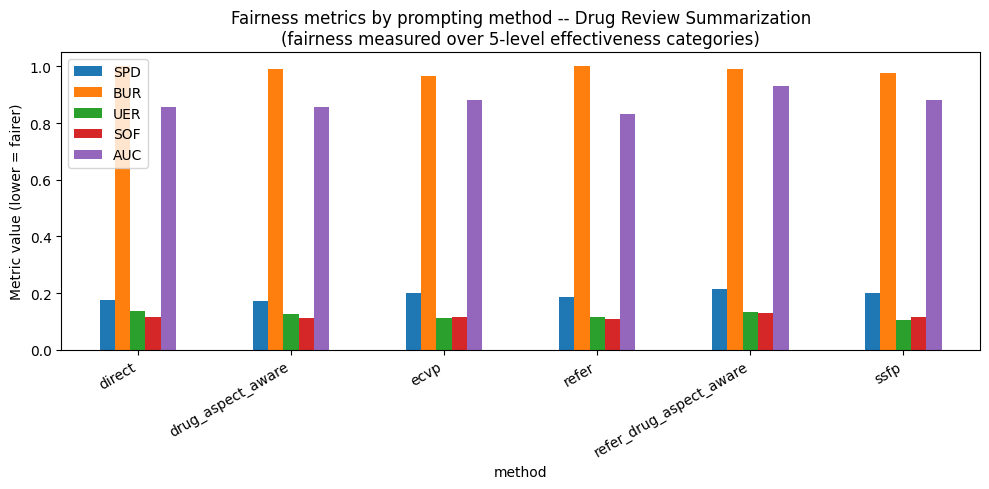

In [ ]:
import matplotlib.pyplot as plt

pivot = method_table.set_index("method")[metrics]
ax = pivot.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("Metric value (lower = fairer)")
ax.set_title("Fairness metrics by prompting method -- Drug Review Summarization\n(fairness measured over 5-level effectiveness categories)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# SAVE FILES FOR FUTURE FAIRNESS / EC / CP / HALLUCINATION
# ============================================================

# ------------------------------------------------------------
# 1. Save full selected samples
# ------------------------------------------------------------
# This preserves the original selected 8 reviews per sample.
# Required for EC, CP, and hallucination checking.
from pathlib import Path
from datetime import datetime
OUTPUT_DIR = Path("/content/drive/MyDrive/drug_summarization_method_A_full_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Saving outputs to:", OUTPUT_DIR)

selected_samples_path = OUTPUT_DIR / "selected_samples_full.json"

with open(selected_samples_path, "w", encoding="utf-8") as f:
    json.dump(samples, f, ensure_ascii=False, indent=2)

print("Saved:", selected_samples_path)

# ------------------------------------------------------------
# 2. Save full generated summary records as JSON
# ------------------------------------------------------------
# This is the most important file.
# It contains: source reviews + source counts + prompt + summary + method.

full_records_path = OUTPUT_DIR / "generated_summary_full_records.json"

with open(full_records_path, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print("Saved:", full_records_path)

# ------------------------------------------------------------
# 3. Save summary-level CSV
# ------------------------------------------------------------
# CSV is easier to open in Excel.
# Nested fields are converted to JSON strings.

summary_csv_df = result_df.copy()

for col in ["source_counts", "source_reviews"]:
    if col in summary_csv_df.columns:
        summary_csv_df[col] = summary_csv_df[col].apply(
            lambda x: json.dumps(x, ensure_ascii=False)
        )

summary_csv_path = OUTPUT_DIR / "generated_summary_summary_level.csv"
summary_csv_df.to_csv(summary_csv_path, index=False)

print("Saved:", summary_csv_path)

# ------------------------------------------------------------
# 4. Save source review-level CSV
# ------------------------------------------------------------
# Each selected source review becomes one row.
# Useful for hallucination, EC, CP, and manual checking.

review_rows = []

for sample in samples:
    for i, review in enumerate(sample["reviews"]):
        review_rows.append({
            "sample_id": sample["sample_id"],
            "product_id": sample["product_id"],
            "condition": sample["condition"],
            "condition_name": sample.get("condition_name", None),
            "review_no": i + 1,
            "review_text": review.get("text", None),
            "rating": review.get("rating", None),
            "binary_label_for_sampling": review.get("label", None),
            "effectiveness": review.get("effectiveness", None),
            "source_counts": json.dumps(sample.get("source_counts", {}), ensure_ascii=False)
        })

source_review_df = pd.DataFrame(review_rows)

source_review_csv_path = OUTPUT_DIR / "selected_source_reviews_review_level.csv"
source_review_df.to_csv(source_review_csv_path, index=False)

print("Saved:", source_review_csv_path)

# ------------------------------------------------------------
# 5. Save experiment metadata
# ------------------------------------------------------------

metadata = {
    "experiment_name": "drug_summarization_method_A",
    "sampling_design": "Method A: sample-level controlled sampling",
    "model_id": MODEL_ID,
    "methods": list(methods.keys()),
    "effectiveness_labels": EFFECTIVENESS_LABELS,
    "number_of_samples": len(samples),
    "number_of_generated_summaries": len(result_df),
    "number_of_source_reviews": len(source_review_df),
    "unique_products": pd.DataFrame(samples)["product_id"].nunique(),
    "sample_condition_distribution": dict(Counter([s["condition"] for s in samples])),
    "summary_method_distribution": result_df["method"].value_counts().to_dict(),
    "created_at": datetime.now().isoformat(),
    "saved_files": {
        "selected_samples_full": str(selected_samples_path),
        "generated_summary_full_records": str(full_records_path),
        "generated_summary_summary_level_csv": str(summary_csv_path),
        "selected_source_reviews_review_level_csv": str(source_review_csv_path),
    }
}

metadata_path = OUTPUT_DIR / "experiment_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Saved:", metadata_path)

print("\n===== SAVE COMPLETED =====")
print("Total samples:", len(samples))
print("Generated summaries:", len(result_df))
print("Selected source reviews:", len(source_review_df))
print("Unique drugs/products:", pd.DataFrame(samples)["product_id"].nunique())
print("\nCondition distribution:")
print(pd.DataFrame(samples)["condition"].value_counts())
print("\nMethod distribution:")
print(result_df["method"].value_counts())

Saving outputs to: /content/drive/MyDrive/drug_summarization_method_A_full_outputs
Saved: /content/drive/MyDrive/drug_summarization_method_A_full_outputs/selected_samples_full.json
Saved: /content/drive/MyDrive/drug_summarization_method_A_full_outputs/generated_summary_full_records.json
Saved: /content/drive/MyDrive/drug_summarization_method_A_full_outputs/generated_summary_summary_level.csv
Saved: /content/drive/MyDrive/drug_summarization_method_A_full_outputs/selected_source_reviews_review_level.csv
Saved: /content/drive/MyDrive/drug_summarization_method_A_full_outputs/experiment_metadata.json

===== SAVE COMPLETED =====
Total samples: 90
Generated summaries: 540
Selected source reviews: 720
Unique drugs/products: 53

Condition distribution:
condition
balanced        30
pro_positive    30
pro_negative    30
Name: count, dtype: int64

Method distribution:
method
refer                      90
direct                     90
ssfp                       90
ecvp                       90
drug

In [ ]:
# ============================================================
# SAVE RESULT_DF AFTER FAIRNESS METRICS ARE CALCULATED
# ============================================================

final_metric_path = OUTPUT_DIR / "generated_summaries_with_fairness_metrics.csv"

metric_save_df = result_df.copy()

for col in ["source_counts", "summary_counts", "source_reviews"]:
    if col in metric_save_df.columns:
        metric_save_df[col] = metric_save_df[col].apply(
            lambda x: json.dumps(x, ensure_ascii=False) if isinstance(x, (dict, list)) else x
        )

metric_save_df.to_csv(final_metric_path, index=False)

print("Saved final fairness metric file:", final_metric_path)

Saved final fairness metric file: /content/drive/MyDrive/drug_summarization_method_A_full_outputs/generated_summaries_with_fairness_metrics.csv


## 12. Save outputs

In [ ]:
result_df.to_csv("drug_review_refer_results.csv", index=False)
summary_table.to_csv("drug_review_refer_metric_summary.csv", index=False)
paper_table.to_csv("drug_review_paper_style_table.csv", index=False)
condition_table.to_csv("drug_review_condition_wise_metric_table.csv", index=False)
overall_improvement.to_csv("drug_review_overall_improvement.csv", index=False)

print("Saved all result tables.")

###Calculating Metrics values from generated summary

In [ ]:
import json
import pandas as pd
import numpy as np
import re
from pathlib import Path
from tqdm import tqdm
from google.colab import drive

drive.mount("/content/drive")

OUTPUT_DIR = Path("/content/drive/MyDrive/drug_summarization_method_A_full_outputs")

full_records_path = OUTPUT_DIR / "generated_summary_full_records.json"

with open(full_records_path, "r", encoding="utf-8") as f:
    records = json.load(f)

result_df = pd.DataFrame(records)

print(result_df.shape)
result_df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(540, 6)


,sample_id,condition,product_id,method,source_counts,summary
0,0,balanced,accutane,refer,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a balanced summary of the reviews:\n\n*...
1,0,balanced,accutane,direct,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a short text summarizing the patient's ...
2,0,balanced,accutane,ssfp,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a balanced summary of the reviews:\n\n*...
3,0,balanced,accutane,ecvp,"{'Highly Effective': 3, 'Moderately Effective'...","Based on the provided reviews, here is a balan..."
4,0,balanced,accutane,drug_aspect_aware,"{'Highly Effective': 3, 'Moderately Effective'...",Here is a 50-word summary:\n\nThis patient exp...


In [ ]:
EFFECTIVENESS_LABELS = [
    "Ineffective",
    "Marginally Effective",
    "Moderately Effective",
    "Considerably Effective",
    "Highly Effective",
]

In [ ]:
import json
import re

LABELS = EFFECTIVENESS_LABELS


def normalize_counts(counts, labels=LABELS):
    """Definition 3.1 (p_x / p_y): normalize raw value counts into a distribution."""
    total = sum(counts.get(label, 0) for label in labels)
    if total == 0:
        return np.zeros(len(labels))
    return np.array([counts.get(label, 0) / total for label in labels])


def _spd(source_dist, summary_dist):
    """Statistical Parity Difference / distribution gap.
    Mean absolute difference between source and summary distributions. Lower is better."""
    return float(np.mean(np.abs(source_dist - summary_dist)))


def _bur(source_dist, summary_dist, tau=0.8):
    """Definition 5.1 -- Binary Unfair Rate.
    Unfair (1) iff ANY value v_k has summary_dist(v_k) < tau * source_dist(v_k)."""
    return int(np.any(summary_dist < tau * source_dist))


def _uer(source_dist, summary_dist):
    """Definition 5.2 -- Unfair Error Rate.
    UER = (1/r) * sum_k max(0, p_x(v_k) - p_y(v_k)). A RAW proportion."""
    return float(np.mean(np.maximum(0.0, source_dist - summary_dist)))


def _auc(source_dist, summary_dist, n_points=10):
    """Definition 5.3 -- Area Under (fairness-threshold) Curve.
    Approximates the integral of BUR over tau in [0,1] using 10 evenly spaced tau samples."""
    taus = [(i + 0.5) / n_points for i in range(n_points)]
    return float(np.mean([_bur(source_dist, summary_dist, tau=t) for t in taus]))


def _sof(source_dist, summary_dist):
    """Definition 5.4 -- Second-Order Fairness.
    S_UER = { max(0, p_x(v_k) - p_y(v_k)) : k in [r] }
    SOF   = (1/r) * sum_{s in S_UER} | s - mean(S_UER) |
    Mean ABSOLUTE deviation -- not standard deviation."""
    under_error = np.maximum(0.0, source_dist - summary_dist)
    return float(np.mean(np.abs(under_error - under_error.mean())))


def calculate_metrics(source_counts, summary_counts, tau=0.8):
    source_dist = normalize_counts(source_counts)
    summary_dist = normalize_counts(summary_counts)

    return {
        "SPD": _spd(source_dist, summary_dist),
        "BUR": _bur(source_dist, summary_dist, tau=tau),
        "UER": _uer(source_dist, summary_dist),
        "AUC": _auc(source_dist, summary_dist),
        "SOF": _sof(source_dist, summary_dist),
    }

In [ ]:
def make_source_text(sample):
    return " || ".join([r["text"] for r in sample["reviews"]])


def _value_list_text(labels=EFFECTIVENESS_LABELS):
    return ", ".join(labels)

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "meta-llama/Llama-3.2-1B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto"
)

# Avoid pad-token warning/error
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token


def generate_text(prompt, max_new_tokens=256):
    messages = [
        {"role": "user", "content": prompt}
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        [text],
        return_tensors="pt",
        truncation=True,
        max_length=7000
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            repetition_penalty=1.10,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_ids = outputs[0][inputs.input_ids.shape[-1]:]

    return tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

In [ ]:
def extract_json(text):
    match = re.search(r"\{.*\}", text, re.DOTALL)
    if match:
        try:
            return json.loads(match.group(0))
        except Exception:
            return None
    return None


def classify_summary_counts(summary):
    values = _value_list_text()
    json_template = ", ".join(f"\"{lbl}\": number" for lbl in EFFECTIVENESS_LABELS)

    prompt = f"""
Classify the patient effectiveness experiences implied by this drug-review summary into the
following levels: {values}.

Return only valid JSON in this exact format (use 0 for any level not represented):
{{{json_template}}}

Summary:
{summary}
""".strip()

    output = generate_text(prompt, max_new_tokens=120)
    parsed = extract_json(output)

    if parsed is None:
        return {label: 0 for label in EFFECTIVENESS_LABELS}

    return {label: int(parsed.get(label, 0)) for label in EFFECTIVENESS_LABELS}


result_df["summary_counts"] = result_df["summary"].apply(classify_summary_counts)

metric_rows = []
for _, row in result_df.iterrows():
    metric_rows.append(calculate_metrics(row["source_counts"], row["summary_counts"]))

metric_df = pd.DataFrame(metric_rows)
result_df = pd.concat([result_df.reset_index(drop=True), metric_df.reset_index(drop=True)], axis=1)

result_df.head()

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


,sample_id,condition,product_id,method,source_counts,summary,summary_counts,SPD,BUR,UER,AUC,SOF
0,0,balanced,accutane,refer,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a balanced summary of the reviews:\n\n*...,"{'Ineffective': 2, 'Marginally Effective': 5, ...",0.114706,1,0.057353,0.5,0.045882
1,0,balanced,accutane,direct,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a short text summarizing the patient's ...,"{'Ineffective': 0, 'Marginally Effective': 0, ...",0.200000,1,0.200000,1.0,0.140000
2,0,balanced,accutane,ssfp,"{'Highly Effective': 3, 'Moderately Effective'...",Here's a balanced summary of the reviews:\n\n*...,"{'Ineffective': 0, 'Marginally Effective': 1, ...",0.205556,1,0.102778,1.0,0.117778
3,0,balanced,accutane,ecvp,"{'Highly Effective': 3, 'Moderately Effective'...","Based on the provided reviews, here is a balan...","{'Ineffective': 0, 'Marginally Effective': 4, ...",0.157895,1,0.078947,1.0,0.094737
4,0,balanced,accutane,drug_aspect_aware,"{'Highly Effective': 3, 'Moderately Effective'...",Here is a 50-word summary:\n\nThis patient exp...,"{'Ineffective': 0, 'Marginally Effective': 2, ...",0.116667,1,0.058333,1.0,0.070000


In [ ]:
metrics = ["SPD", "BUR", "UER", "SOF", "AUC"]
method_table = (
    result_df
    .groupby("method", as_index=False)[metrics]
    .mean()
    .round(4)
)

method_table

,method,SPD,BUR,UER,SOF,AUC
0,direct,0.1761,1.0000,0.1358,0.1167,0.8556
1,drug_aspect_aware,0.1709,0.9889,0.1255,0.1123,0.8578
2,ecvp,0.2004,0.9667,0.1124,0.1146,0.8811
3,refer,0.1857,1.0000,0.1162,0.1086,0.8311
4,refer_drug_aspect_aware,0.2152,0.9889,0.1332,0.1298,0.9322
5,ssfp,0.1997,0.9778,0.1065,0.1156,0.8811
